# 1. Bayesian Regression

##  (a) Sequential Bayesian Update

In [3]:
# importing libraries
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Setting seed for reproducibility
np.random.seed(42)

In [5]:
# Generate the dataset with N=100
N=100
x_values = np.random.uniform(0, 1, N)
noise = np.random.normal(0, 0.1, N)
y_values = np.sin(2 * np.pi * x_values) + noise
x_data, y_data = x_values, y_values

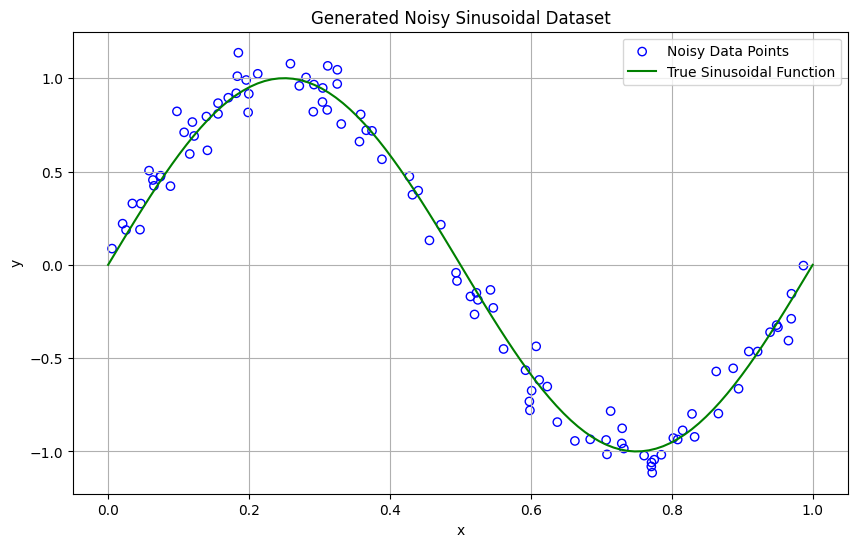

In [6]:
# Plotting the generated data points just for the purpose of visualization
plt.figure(figsize=(10, 6))
plt.scatter(x_data, y_data, facecolors='none', edgecolors='b', label='Noisy Data Points')
x_true = np.linspace(0, 1, 100)
y_true = np.sin(2 * np.pi * x_true)
plt.plot(x_true, y_true, 'g', label='True Sinusoidal Function')
plt.title('Generated Noisy Sinusoidal Dataset')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.show()

**Bayesian Sequential Updates and Implementation**

**What we need to do Here is :**
To fit a 25th-order linear regression model with Gaussian basis functions using a Bayesian approach. We will sequentially update the posterior distribution of the model weights, $ \mathbf{w} $, as each new data point is observed.


* **Likelihood:**  
  The probability of observing a target $ t $ given an input $ x $ and weights $ \mathbf{w} $ is modeled as a Gaussian distribution:

  $$
  p(t \mid x, \mathbf{w}, \beta) = \mathcal{N}\big(t \mid \mathbf{w}^T \boldsymbol{\phi}(x), \beta^{-1}\big)
  $$

  where $ \boldsymbol{\phi}(x) $ is the feature vector from the Gaussian basis functions, and  
  $ \beta = (1/0.1)^2 = 100 $ is the precision of the noise.

* **Prior:**  
  We assume a zero-mean isotropic Gaussian prior over the weights:

  $$
  p(\mathbf{w} \mid \alpha) = \mathcal{N}\big(\mathbf{w} \mid \mathbf{m}_0, \mathbf{S}_0\big)
  $$

  we will be using a standard normal prior, so  
  $ \mathbf{m}_0 = \mathbf{0} $ and $ \mathbf{S}_0 = \alpha^{-1}\mathbf{I} = \mathbf{I} $ (since $ \alpha = 1 $).

---

#### **Derivation of Recursive Update Equations**

The core idea of sequential Bayesian learning is that the posterior distribution after observing $ N-1 $ data points becomes the prior for the $ N $-th data point.

Let the posterior after observing $ N-1 $ points be  
$ \mathcal{N}(\mathbf{w} \mid \mathbf{m}_{N-1}, \mathbf{S}_{N-1}) $.  
When we observe a new data point $ (\mathbf{x}_N, t_N) $, we update our belief using Bayes' theorem:

$$
p(\mathbf{w} \mid \mathcal{D}_N)
\propto
\underbrace{p(t_N \mid \mathbf{w}, \mathbf{x}_N, \beta)}_{\text{Likelihood of new point}}
\times
\underbrace{p(\mathbf{w} \mid \mathcal{D}_{N-1})}_{\text{Current Prior (Posterior from N-1 points)}}
$$

Since the prior and likelihood are both Gaussian, the resulting posterior will also be Gaussian:

$$
p(\mathbf{w} \mid \mathcal{D}_N)
= \mathcal{N}\big(\mathbf{w} \mid \mathbf{m}_N, \mathbf{S}_N\big)
$$

The updated parameters are given by the recursive equations:

$$
\mathbf{S}_N^{-1}
= \mathbf{S}_{N-1}^{-1}
+ \beta \, \boldsymbol{\phi}(\mathbf{x}_N) \boldsymbol{\phi}(\mathbf{x}_N)^T
$$

$$
\mathbf{m}_N
= \mathbf{S}_N \big(\mathbf{S}_{N-1}^{-1}\mathbf{m}_{N-1}
+ \beta \, t_N \, \boldsymbol{\phi}(\mathbf{x}_N)\big)
$$

For the first step ($ N = 1 $), we use $ \mathbf{m}_0 $ and $ \mathbf{S}_0 $ as the prior parameters.


In [7]:
# function to compute the probability density function of a Gaussian distribution.
def norm_pdf(x, mean, std):
    if std == 0:
        return np.inf if x == mean else 0
    variance = std**2
    coefficient = 1.0 / np.sqrt(2 * np.pi * variance)
    exponent = -((x - mean)**2) / (2 * variance)
    return coefficient * np.exp(exponent)

In [8]:
# defining the model and basis function parameters
N_BASIS = 24
MODEL_ORDER = N_BASIS + 1 # 24 basis functions + 1 bias term
BETA = (1 / 0.1)**2        # precision of the noise
ALPHA = 1.0                # precision of the prior

# defining the centers mu_j for the Gaussian basis functions
mu_j = np.linspace(0, 1, N_BASIS)


# fix the width sigma based on the spacing between centers
sigma = mu_j[1] - mu_j[0]

# function to computes the value of a single Gaussian basis function
def gaussian_basis_function(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma)**2)


# function to construct the design matrix (feature vector) phi(x) for a single input x
def design_matrix(x):
    phi = np.ones(MODEL_ORDER)
    for j in range(N_BASIS):
        phi[j+1] = gaussian_basis_function(x, mu_j[j], sigma)
    return phi

In [9]:
# initializing the prior distribution for the weights w ~ N(m0, S0)
m0 = np.zeros(MODEL_ORDER)
S0 = np.identity(MODEL_ORDER) / ALPHA

# setting the initial posterior parameters to the prior parameters
m_N = m0
S_N = S0

# storing the marginal distribution of w5 for visualization
w5_marginals = []

# Sequentially update the posterior for each data point
for i in range(len(x_data)):
    x_i, y_i = x_data[i], y_data[i]
    phi_i = design_matrix(x_i).reshape(-1, 1)
    
    S_inv_prev = np.linalg.inv(S_N)
    S_inv_new = S_inv_prev + BETA * (phi_i @ phi_i.T)
    S_N = np.linalg.inv(S_inv_new)
    
    m_N = S_N @ (S_inv_prev @ m_N + BETA * y_i * phi_i.flatten())
    
    # storing the marginal distribution of w5 every 10th update
    if (i + 1) % 10 == 0:
        w5_mean = m_N[5]
        w5_std = np.sqrt(S_N[5, 5])
        w5_marginals.append((w5_mean, w5_std))

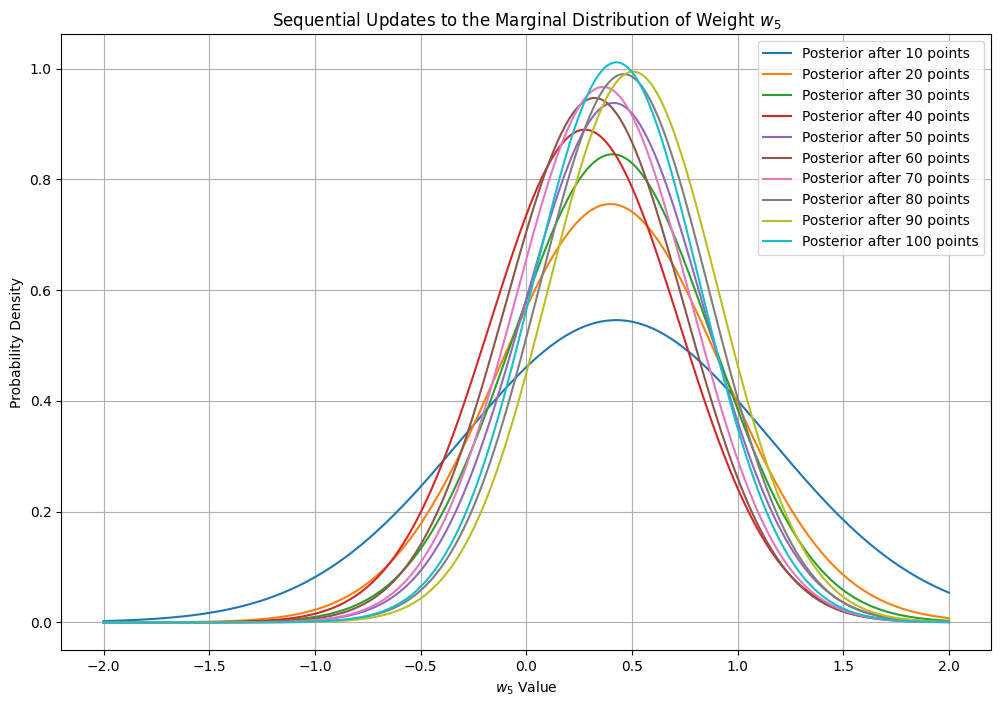


Final Posterior Mean (m_N) for w0-w4:
 [ 0.06993209 -0.01894452  0.00793383  0.35864532  0.1283188 ]

Final Posterior Covariance (S_N) for w0-w4 (top-left 5x5 corner):
 [[ 0.17550335 -0.13002123 -0.03527673 -0.08826166 -0.0609119 ]
 [-0.13002123  0.14516261 -0.03897841  0.12661707 -0.00358975]
 [-0.03527673 -0.03897841  0.10440811 -0.08228213  0.09740427]
 [-0.08826166  0.12661707 -0.08228213  0.15954649 -0.07795469]
 [-0.0609119  -0.00358975  0.09740427 -0.07795469  0.13932286]]


In [10]:
# Visualization of w5 distribution updates using custom PDF function
plt.figure(figsize=(12, 8))
x_axis = np.linspace(-2, 2, 400)

for i, (mean, std) in enumerate(w5_marginals):
    pdf = norm_pdf(x_axis, mean, std)
    update_num = (i + 1) * 10
    plt.plot(x_axis, pdf, label=f'Posterior after {update_num} points')

plt.title('Sequential Updates to the Marginal Distribution of Weight $w_5$')
plt.xlabel('$w_5$ Value')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(True)
plt.show()

print("\nFinal Posterior Mean (m_N) for w0-w4:\n", m_N[:5])
print("\nFinal Posterior Covariance (S_N) for w0-w4 (top-left 5x5 corner):\n", S_N[:5, :5])


##  (b) MAP Sampling and Curve Fits

In [11]:
M = 20
x_dense = np.linspace(0, 1, 200)

# drawing 20 samples from the posterior and compute their curves
sampled_curves = np.zeros((M, len(x_dense)))
for i in range(M):
    w_sample = np.random.multivariate_normal(mean=m_N, cov=S_N)
    
    # Compute the regression curve for this sample
    y_curve = np.array([design_matrix(x) @ w_sample for x in x_dense])
    sampled_curves[i, :] = y_curve

# Compute the average of the sampled curves
average_curve = np.mean(sampled_curves, axis=0)

# defining the true sinusoidal function for comparison
y_true = np.sin(2 * np.pi * x_dense)

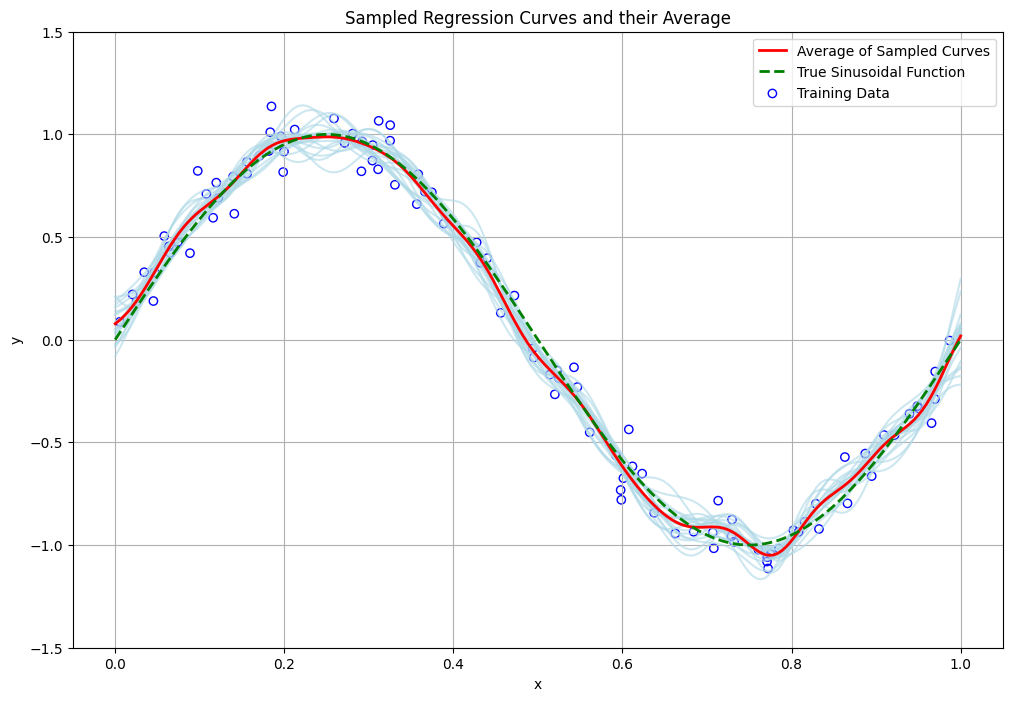

In [12]:
# Plotting the results
plt.figure(figsize=(12, 8))

# Plotting the 20 sampled curves
for i in range(M):
    plt.plot(x_dense, sampled_curves[i, :], color='lightblue', alpha=0.6)

# Plotting the average curve and the true function
plt.plot(x_dense, average_curve, color='red', linewidth=2, label='Average of Sampled Curves')
plt.plot(x_dense, y_true, color='green', linestyle='--', linewidth=2, label='True Sinusoidal Function')
plt.scatter(x_data, y_data, facecolors='none', edgecolors='b', label='Training Data')

plt.title('Sampled Regression Curves and their Average')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.ylim(-1.5, 1.5)
plt.grid(True)
plt.show()



## (c) Posterior Predictive Distribution 

In [13]:
def norm_pdf(x, mean, std):
    variance = std**2
    coefficient = 1.0 / np.sqrt(2 * np.pi * variance)
    exponent = -((x - mean)**2) / (2 * variance)
    return coefficient * np.exp(exponent)

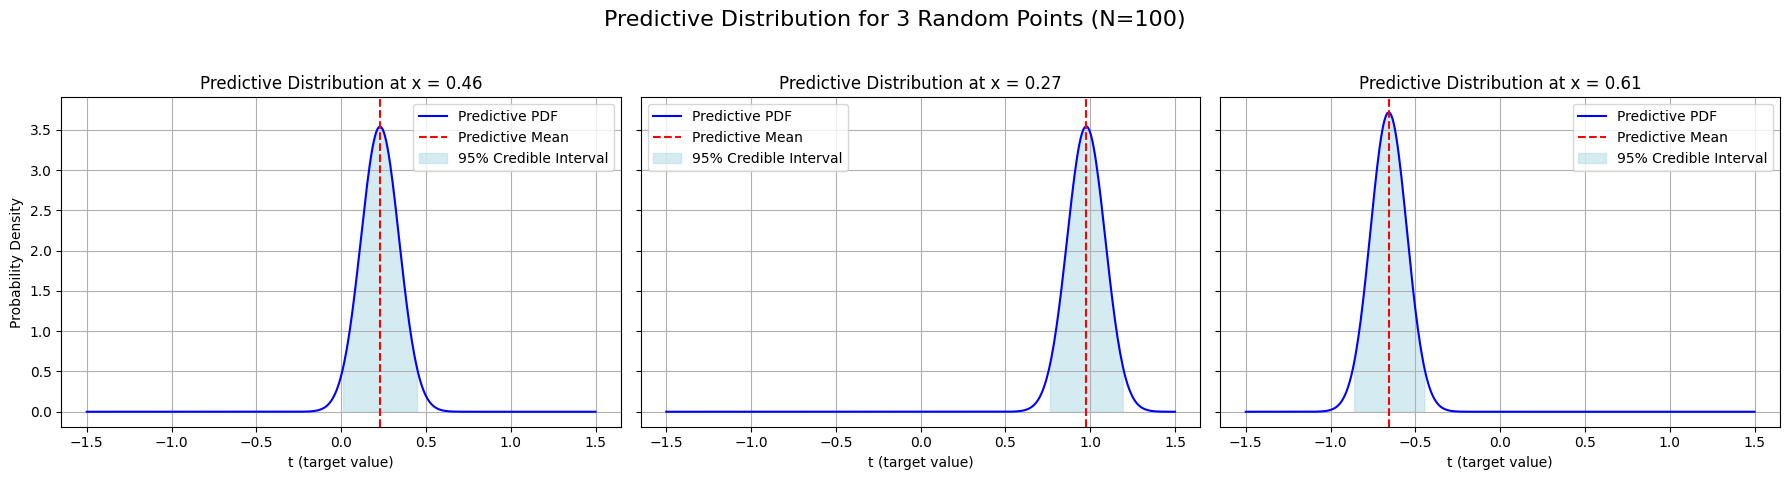

In [14]:
def plot_predictive_distribution_for_points(x_data, y_data, selected_indices):

    # this function will calculates and plots the predictive distribution for specific data points,including the mean and 95% credible interval.

    # First we will compute the final posterior using the full dataset (N=100)
    m0 = np.zeros(MODEL_ORDER)
    S0 = np.identity(MODEL_ORDER) / ALPHA
    m_N, S_N = m0, S0

    for i in range(len(x_data)):
        phi_i = design_matrix(x_data[i]).reshape(-1, 1)
        S_inv_prev = np.linalg.inv(S_N)
        S_inv_new = S_inv_prev + BETA * (phi_i @ phi_i.T)
        S_N = np.linalg.inv(S_inv_new)
        m_N = S_N @ (S_inv_prev @ m_N + BETA * y_data[i] * phi_i.flatten())

    # Plotting for the selected points
    fig, axes = plt.subplots(1, len(selected_indices), figsize=(18, 5), sharey=True)
    t_range = np.linspace(-1.5, 1.5, 400) 

    for i, index in enumerate(selected_indices):
        x_point = x_data[index]
        phi_point = design_matrix(x_point)

        # Calculating predictive mean and variance for the point
        pred_mean = phi_point.T @ m_N
        pred_var = (1 / BETA) + (phi_point.T @ S_N @ phi_point)
        pred_std = np.sqrt(pred_var)

        # Plotting the PDF
        ax = axes[i]
        pdf_values = norm_pdf(t_range, pred_mean, pred_std)
        ax.plot(t_range, pdf_values, color='blue', label='Predictive PDF')
        ax.axvline(pred_mean, color='red', linestyle='--', label='Predictive Mean')

        # Shading the 95% credible interval
        lower_bound = pred_mean - 1.96 * pred_std
        upper_bound = pred_mean + 1.96 * pred_std
        ax.fill_between(t_range, pdf_values, where=(t_range >= lower_bound) & (t_range <= upper_bound),
                        color='lightblue', alpha=0.5, label='95% Credible Interval')

        ax.set_title(f'Predictive Distribution at x = {x_point:.2f}')
        ax.set_xlabel('t (target value)')
        if i == 0:
            ax.set_ylabel('Probability Density')
        ax.legend()
        ax.grid(True)
    plt.suptitle('Predictive Distribution for 3 Random Points (N=100)', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# here we will select and plot for 3 random indices from the dataset
random_indices = np.random.choice(len(x_data), 3, replace=False)
plot_predictive_distribution_for_points(x_data, y_data, random_indices)


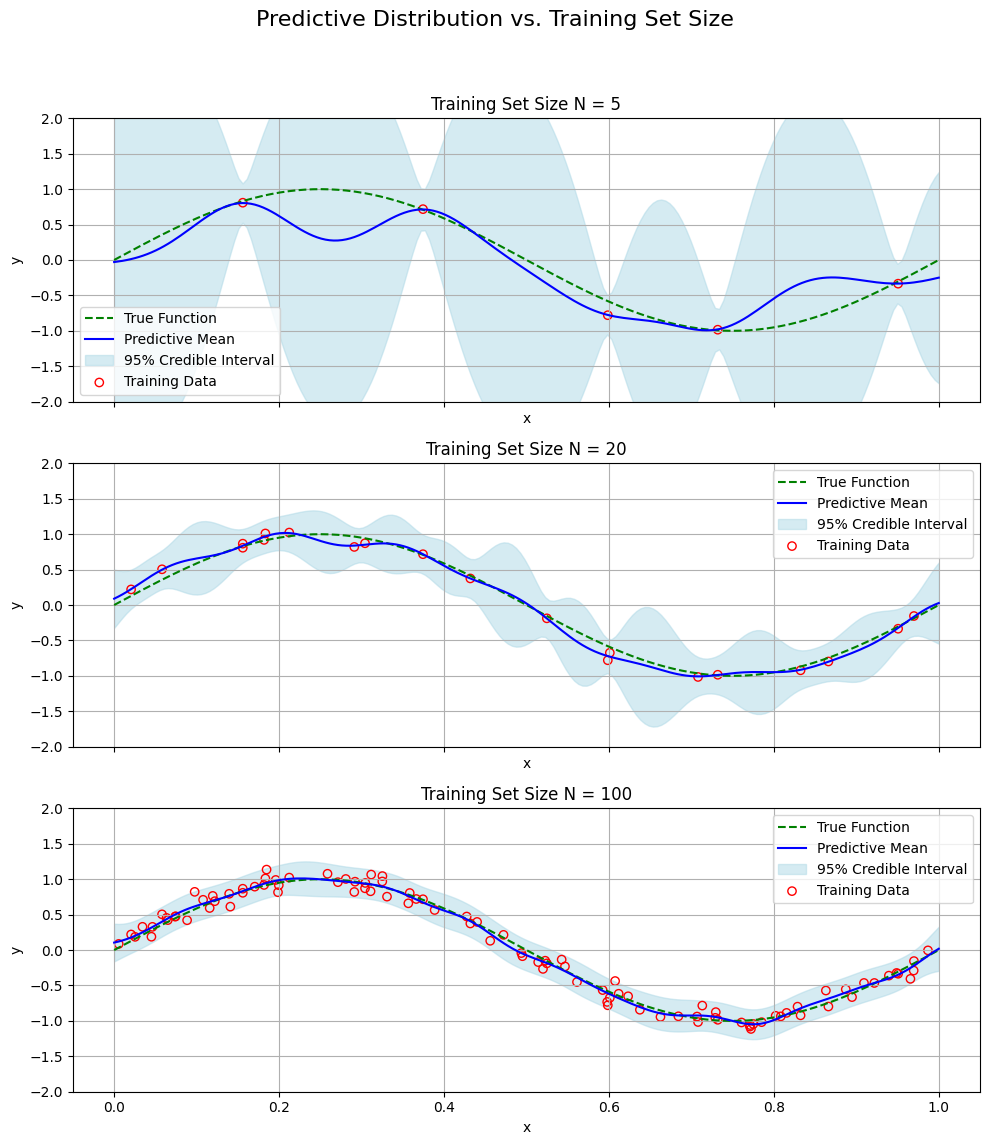

In [17]:
def plot_predictive_mean_with_uncertainty(training_sizes):

    # this function plots the predictive mean and its 95% credible interval for different training set sizes.
    x_dense = np.linspace(0, 1, 200)
    y_true = np.sin(2 * np.pi * x_dense)
    fig, axes = plt.subplots(len(training_sizes), 1, figsize=(10, 12), sharex=True)

    for i, N in enumerate(training_sizes):
        x_train, y_train = x_data[:N], y_data[:N]

        # computing the posterior for this subset size
        m0 = np.zeros(MODEL_ORDER)
        S0 = np.identity(MODEL_ORDER) / ALPHA
        m_N_sub, S_N_sub = m0, S0

        if N > 0:
            # recomputing the posterior for the subset of data
            for j in range(N):
                phi_j = design_matrix(x_train[j]).reshape(-1, 1)
                S_inv_prev = np.linalg.inv(S_N_sub)
                S_inv_new = S_inv_prev + BETA * (phi_j @ phi_j.T)
                S_N_sub = np.linalg.inv(S_inv_new)
                m_N_sub = S_N_sub @ (S_inv_prev @ m_N_sub + BETA * y_train[j] * phi_j.flatten())

        # Calculate predictive mean and std dev over the dense grid
        pred_means = []
        pred_stds = []
        for x_val in x_dense:
            phi_val = design_matrix(x_val)
            mean = phi_val.T @ m_N_sub
            var = (1 / BETA) + (phi_val.T @ S_N_sub @ phi_val)
            pred_means.append(mean)
            pred_stds.append(np.sqrt(var))

        pred_means = np.array(pred_means)
        pred_stds = np.array(pred_stds)

        # Plotting
        ax = axes[i]
        ax.plot(x_dense, y_true, 'g--', label='True Function')
        ax.plot(x_dense, pred_means, 'b-', label='Predictive Mean')
        ax.fill_between(x_dense, pred_means - 1.96 * pred_stds, pred_means + 1.96 * pred_stds,
                        color='lightblue', alpha=0.5, label='95% Credible Interval')
        ax.scatter(x_train, y_train, facecolors='none', edgecolors='r', label='Training Data')
        ax.set_title(f'Training Set Size N = {N}')
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.legend()
        ax.grid(True)
        ax.set_ylim(-2, 2)

    plt.suptitle('Predictive Distribution vs. Training Set Size', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# runnig the function for N = {5, 20, 100}
plot_predictive_mean_with_uncertainty([5, 20, 100])

***Observations from the above experiments***

**1. Uncertainty Decreases with More Data**

- The most significant finding is that the models **uncertainty diminishes** as the size of the training dataset (**N**) increases.  
- This is visually demonstrated by the **narrowing of the 95% credible interval** (the shaded region).  
- With a small dataset (**N = 5**), the interval is wide  signifying high uncertainty.  
- As the dataset grows to **N = 100**, the interval becomes much tighter around the mean.

---

**2. Accuracy of the Mean Improves**

- The **predictive mean curve** (solid blue line) becomes a more accurate representation of the **true sinusoidal function** (dashed green line) as more data is provided.  

| Dataset Size | Observation |
|---------------|-------------|
| **N = 5**     | Fit is poor, indicating significant bias. |
| **N = 20**    | Fit improves noticeably. |
| **N = 100**   | Predictive mean closely follows the true function, especially in regions with data points. |

---

**3. Uncertainty is Data-Dependent**

- The **credible interval is narrowest near observed training data points**.  
- In regions of the input space where data is **sparse or absent**, the models uncertainty increases, widening the shaded band.  
- This demonstrates a key strength of **Bayesian regression**  the model inherently recognizes the limits of its knowledge (knows what it doesnt know).

---

### **From the above we can observe that**

 Bayesian regression models **refine their beliefs** as more evidence (data) is introduced  resulting in predictions that are both **more accurate** and **more confident**.


# 2. Understanding Bias-Variance Trade-off

In [19]:
# below is the number of datasets, data points per dataset, model order
L, N, N_BASIS = 100, 25, 24
MODEL_ORDER = N_BASIS + 1

In [20]:
# Gaussian basis function parameters
mu_j = np.linspace(0, 1, N_BASIS)        # Centers
sigma = mu_j[1] - mu_j[0]                # Width as spacing

def gaussian_basis_function(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma)**2)

def design_matrix(x):
    phi = np.ones(MODEL_ORDER)
    for j in range(N_BASIS):
        phi[j+1] = gaussian_basis_function(x, mu_j[j], sigma)
    return phi

In [21]:
# Generating L=100 independent datasets of N=25 points
datasets = []
for _ in range(L):
    x_vals = np.random.uniform(0, 1, N)
    noise = np.random.normal(0, 0.1, N)  
    y_vals = np.sin(2 * np.pi * x_vals) + noise
    datasets.append((x_vals, y_vals))

In [22]:
# regularization strengths 
lambdas = {'low': 1e-5, 'mid': 1e-1, 'high': 1e2}

In [23]:
# Ridge regression using closed-form solution
def fit_ridge_regression(x_vals, y_vals, lambd):
    Phi = np.vstack([design_matrix(x) for x in x_vals])
    I = np.identity(MODEL_ORDER)
    w = np.linalg.inv(Phi.T @ Phi + lambd * I) @ (Phi.T @ y_vals)
    return w

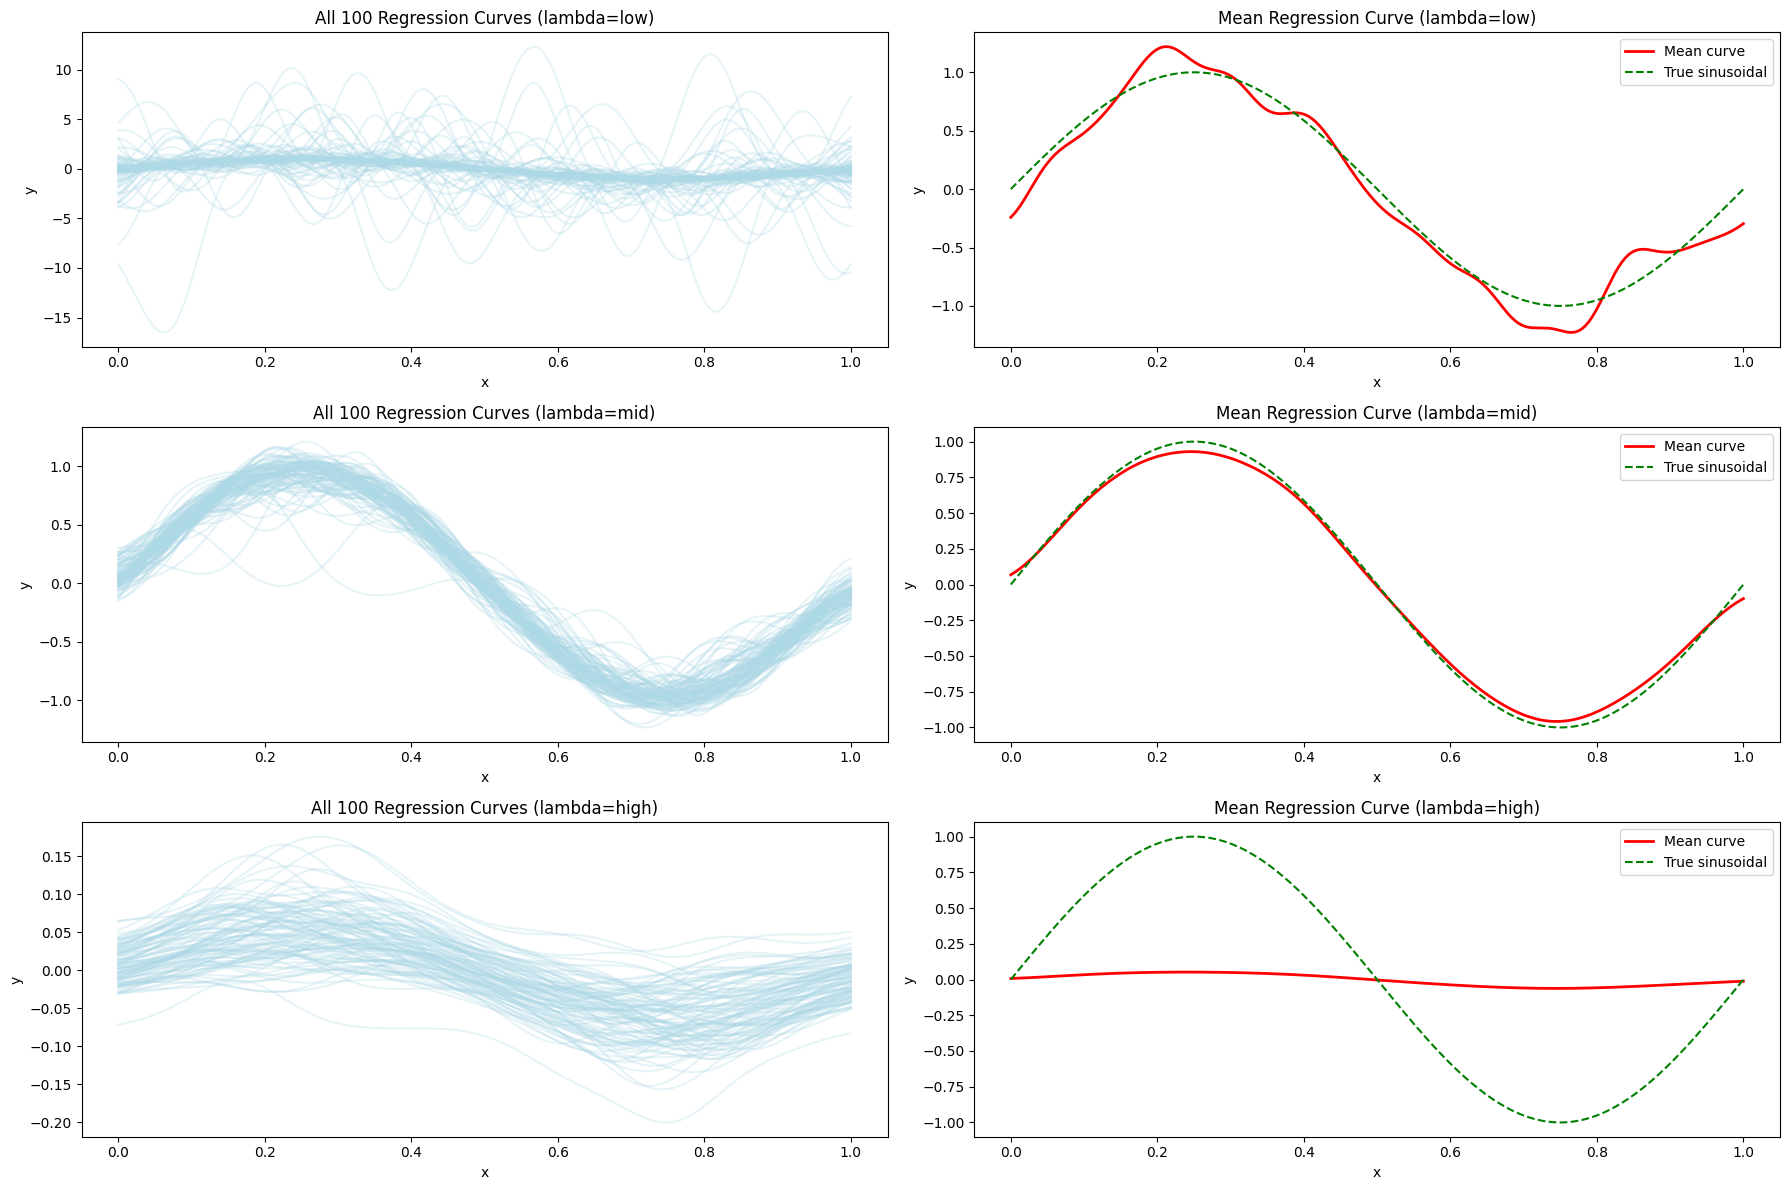

In [24]:
x_plot = np.linspace(0, 1, 200)     
results = {}
for key, lambd in lambdas.items():
    weights_all = []
    for (x_vals, y_vals) in datasets:
        w = fit_ridge_regression(x_vals, y_vals, lambd)
        weights_all.append(w)
    weights_all = np.array(weights_all)
    # Evaluating the learned curves
    curves = np.array([[design_matrix(x) @ w for x in x_plot] for w in weights_all])
    mean_curve = curves.mean(axis=0)
    results[key] = {'weights': weights_all, 'curves': curves, 'mean_curve': mean_curve}

# plotting results according to project
plt.figure(figsize=(18, 12))
for i, key in enumerate(['low', 'mid', 'high'], 1):
    # plotting all 100 estimated curves (left)
    plt.subplot(3, 2, 2 * i - 1)
    for curve in results[key]['curves']:
        plt.plot(x_plot, curve, color='lightblue', alpha=0.3)
    plt.title(f'All 100 Regression Curves (lambda={key})')
    plt.xlabel('x')
    plt.ylabel('y')

    # plotting mean curve and original sinusoidal (right)
    plt.subplot(3, 2, 2 * i)
    plt.plot(x_plot, results[key]['mean_curve'], color='red', linewidth=2, label='Mean curve')
    plt.plot(x_plot, np.sin(2 * np.pi * x_plot), 'g--', label='True sinusoidal')
    plt.title(f'Mean Regression Curve (lambda={key})')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
plt.tight_layout()
plt.show()


Observations on Bias and Variance as Lambda Changes

**Low Lambda (Near Zero)**

- **Variance:** High  
  Each fitted curve closely matches its noisy dataset, leading to wild oscillations and high variability among the 100 curves.  

- **Bias:** Low  
  The mean of the learned models tracks the true sinusoidal function very well.  

- **Overall:**  
  **Overfitting regime**  low bias, high variance.  

---

**Mid Lambda (Moderate)**

- **Variance:** Decreases  
  The 100 curves show less spread, decreasing the model's sensitivity to noise.  

- **Bias:** Increases slightly  
  The mean curve dampens some oscillations but still follows the true function closely.  

- **Overall:**  
  **Good trade-off**  variance is reduced with only a small increase in bias.  

---

**High Lambda (Strong Regularization)**

- **Variance:** Very low  
  All curves are similar and stable, barely affected by random noise in datasets.  

- **Bias:** High  
  The mean curve is overly smooth and fails to capture the true oscillations of the sinusoidal function.  

- **Overall:**  
  **Underfitting regime**  low variance, high bias.  

---

### **From the above we can observe the following:**

As **regularization strength ()** increases:
- **Variance decreases**
- **Bias increases**

# 3. Understanding Generative Models and Discriminant Functions

In [29]:
from sklearn.model_selection import train_test_split

np.random.seed(42)
mean0 = [0, 0]
cov0 = [[1.0, 0.5], [0.5, 1.0]]
mean1 = [2, 2]
cov1 = [[1.0, -0.5], [-0.5, 1.0]]
n_samples = 250

X0 = np.random.multivariate_normal(mean0, cov0, n_samples)
X1 = np.random.multivariate_normal(mean1, cov1, n_samples)
y0 = np.zeros(n_samples)
y1 = np.ones(n_samples)

X = np.vstack((X0, X1))
y = np.hstack((y0, y1))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)


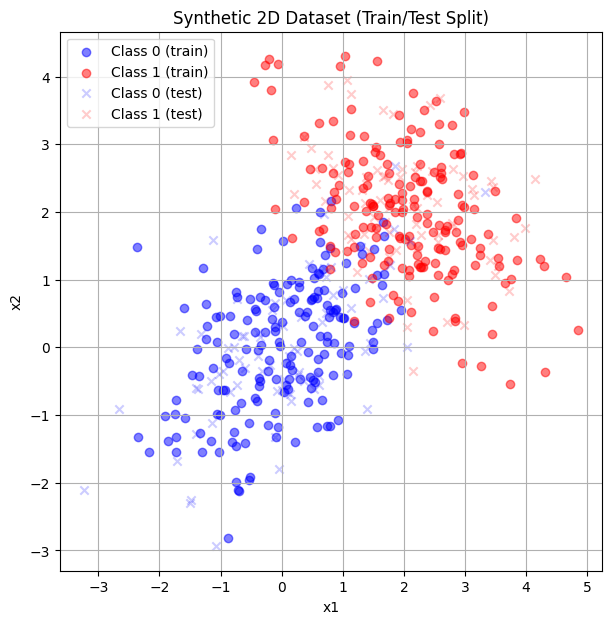

In [ ]:
# plotting the dataset
plt.figure(figsize=(7, 7))
plt.scatter(X_train[y_train==0][:,0], X_train[y_train==0][:,1], color='blue', alpha=0.5, label='Class 0 (train)')
plt.scatter(X_train[y_train==1][:,0], X_train[y_train==1][:,1], color='red', alpha=0.5, label='Class 1 (train)')
plt.scatter(X_test[y_test==0][:,0], X_test[y_test==0][:,1], color='blue', alpha=0.2, marker='x', label='Class 0 (test)')
plt.scatter(X_test[y_test==1][:,0], X_test[y_test==1][:,1], color='red', alpha=0.2, marker='x', label='Class 1 (test)')
plt.legend()
plt.title('Synthetic 2D Dataset (Train/Test Split)')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid(True)
plt.show()

In [32]:
# Gaussian Naive Bayes (GNB)
class GaussianNaiveBayes:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.means = {}
        self.vars = {}
        self.priors = {}
        for c in self.classes:
            X_c = X[y == c]
            self.means[c] = X_c.mean(axis=0)
            self.vars[c] = X_c.var(axis=0) + 1e-6
            self.priors[c] = X_c.shape[0] / X.shape[0]
    def predict(self, X):
        return np.array([self._predict_single(x) for x in X])
    def _predict_single(self, x):
        posteriors = []
        for c in self.classes:
            prior = np.log(self.priors[c])
            likelihood = -0.5 * np.sum(np.log(2 * np.pi * self.vars[c]))
            likelihood -= 0.5 * np.sum(((x - self.means[c]) ** 2) / self.vars[c])
            posteriors.append(prior + likelihood)
        return self.classes[np.argmax(posteriors)]
gnb = GaussianNaiveBayes()
gnb.fit(X_train, y_train)

In [33]:
# Bernoulli Naive Bayes (BNB)
class BernoulliNaiveBayes:
    def fit(self, X, y, threshold=0.0):
        self.classes = np.unique(y)
        self.probs = {}
        self.priors = {}
        X_bin = (X > threshold).astype(int)
        for c in self.classes:
            X_c = X_bin[y == c]
            self.probs[c] = (X_c.sum(axis=0) + 1) / (X_c.shape[0] + 2)
            self.priors[c] = X_c.shape[0] / X_bin.shape[0]
    def predict(self, X, threshold=0.0):
        X_bin = (X > threshold).astype(int)
        return np.array([self._predict_single(x) for x in X_bin])
    def _predict_single(self, x):
        posteriors = []
        for c in self.classes:
            prior = np.log(self.priors[c])
            likelihood = np.sum(x * np.log(self.probs[c]) + (1 - x) * np.log(1 - self.probs[c]))
            posteriors.append(prior + likelihood)
        return self.classes[np.argmax(posteriors)]

bnb = BernoulliNaiveBayes()
bnb.fit(X_train, y_train)


In [34]:
# Linear Discriminant Analysis (LDA, least-squares approach)
class LinearDiscriminantAnalysis:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.means = {}
        self.cov = np.zeros((X.shape[1], X.shape[1]))
        self.priors = {}
        for c in self.classes:
            X_c = X[y == c]
            self.means[c] = X_c.mean(axis=0)
            self.priors[c] = X_c.shape[0] / X.shape[0]
            self.cov += np.cov(X_c, rowvar=False) * (X_c.shape[0] - 1)
        self.cov /= (len(y) - len(self.classes))
        self.inv_cov = np.linalg.inv(self.cov)
    def predict(self, X):
        return np.array([self._predict_single(x) for x in X])
    def _predict_single(self, x):
        scores = []
        for c in self.classes:
            mean = self.means[c]
            prior = np.log(self.priors[c])
            score = x @ self.inv_cov @ mean - 0.5 * mean @ self.inv_cov @ mean + prior
            scores.append(score)
        return self.classes[np.argmax(scores)]

lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)


In [35]:
# L2 regularization with LDA
class L2RegularizedLDA:
    def __init__(self, reg_lambda=0.1):
        self.reg_lambda = reg_lambda
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.means = {}
        self.cov = np.zeros((X.shape[1], X.shape[1]))
        self.priors = {}
        for c in self.classes:
            X_c = X[y == c]
            self.means[c] = X_c.mean(axis=0)
            self.priors[c] = X_c.shape[0] / X.shape[0]
            self.cov += np.cov(X_c, rowvar=False) * (X_c.shape[0] - 1)
        self.cov /= (len(y) - len(self.classes))
        self.cov += self.reg_lambda * np.eye(X.shape[1])
        self.inv_cov = np.linalg.inv(self.cov)
    def predict(self, X):
        return np.array([self._predict_single(x) for x in X])
    def _predict_single(self, x):
        scores = []
        for c in self.classes:
            mean = self.means[c]
            prior = np.log(self.priors[c])
            score = x @ self.inv_cov @ mean - 0.5 * mean @ self.inv_cov @ mean + prior
            scores.append(score)
        return self.classes[np.argmax(scores)]

lda_reg = L2RegularizedLDA(reg_lambda=0.1)
lda_reg.fit(X_train, y_train)



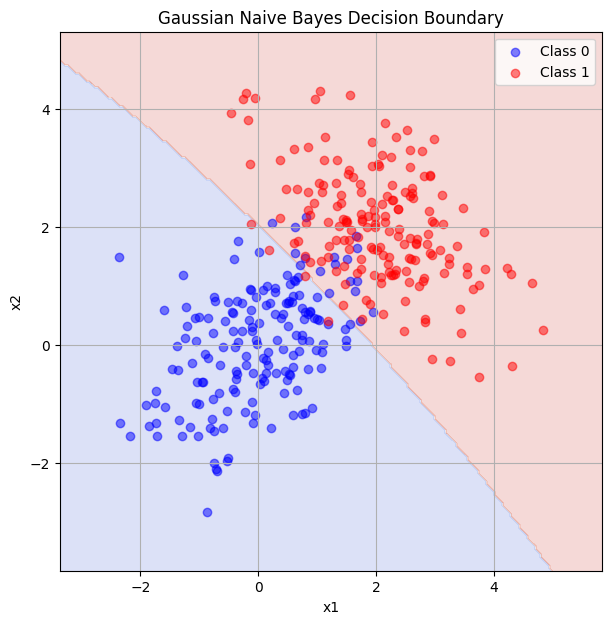

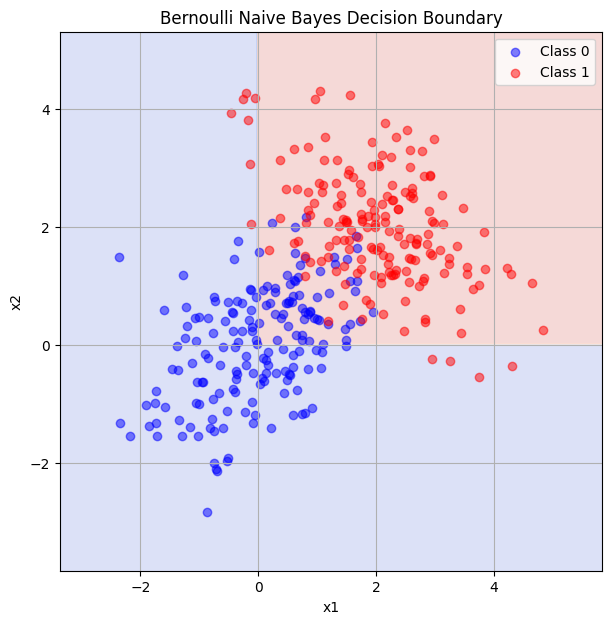

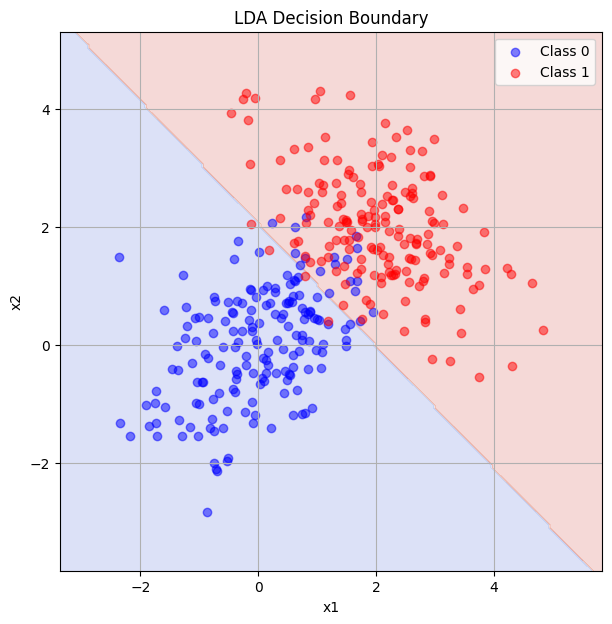

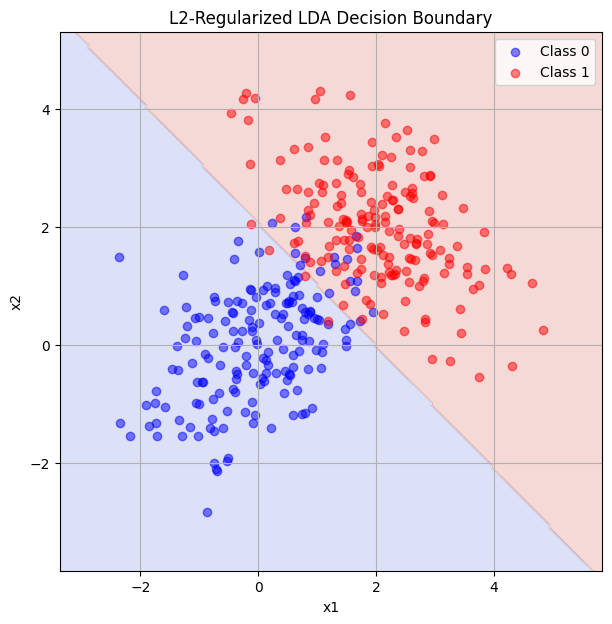

In [36]:
def plot_decision_boundary(clf, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = clf.predict(grid)
    Z = Z.reshape(xx.shape)
    plt.figure(figsize=(7, 7))
    plt.contourf(xx, yy, Z, alpha=0.2, cmap=plt.cm.coolwarm)
    plt.scatter(X[y==0][:,0], X[y==0][:,1], color='blue', alpha=0.5, label='Class 0')
    plt.scatter(X[y==1][:,0], X[y==1][:,1], color='red', alpha=0.5, label='Class 1')
    plt.title(title)
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.grid(True)
    plt.show()

plot_decision_boundary(gnb, X_train, y_train, 'Gaussian Naive Bayes Decision Boundary')
plot_decision_boundary(bnb, X_train, y_train, 'Bernoulli Naive Bayes Decision Boundary')
plot_decision_boundary(lda, X_train, y_train, 'LDA Decision Boundary')
plot_decision_boundary(lda_reg, X_train, y_train, 'L2-Regularized LDA Decision Boundary')


***verification***

In [ ]:
# For gaussian Naive Bayes (GNB)

# test sample
idx = 0
x_sample = X_test[idx]
y_true = y_test[idx]

# calculation for class 0 and class 1
c = 0
mu = gnb.means[c]
var = gnb.vars[c]
manual_loglike = -0.5 * np.sum(np.log(2 * np.pi * var)) \
                  - 0.5 * np.sum(((x_sample - mu) ** 2) / var)
print(f"Manual log-likelihood (class 0): {manual_loglike}")

# we will get score from code's internal calculation
# and we will use the same calculation as in GaussianNaiveBayes._predict_single
prior = np.log(gnb.priors[c])
code_score = prior + manual_loglike
print(f"Manual log-posterior (class 0): {code_score}")

Manual log-likelihood (class 0): -7.027654145830594
Manual log-posterior (class 0): -7.720801326390539


In [ ]:
# for bernoulli naive bayes (BNB)

threshold = 0.0  # using the same threshold as in fit()
x_bin = (X_test[idx] > threshold).astype(int)
c = 0
# Get class-conditional probabilities from model
theta = bnb.probs[c]
manual_prob_product = np.prod(theta**x_bin * (1-theta)**(1-x_bin))
print(f"Manual probability (class 0): {manual_prob_product}")
# Compare to log-prob as done in BernoulliNaiveBayes._predict_single
manual_log_prob = np.sum(x_bin * np.log(theta) + (1 - x_bin) * np.log(1 - theta))
print(f"Manual log-probability (class 0): {manual_log_prob}")
# Compare versus class 0 posterior score inside classifier
prior = np.log(bnb.priors[c])
code_score = prior + manual_log_prob
print(f"Manual log-posterior (class 0): {code_score}")


Manual probability (class 0): 0.27594241756838717
Manual log-probability (class 0): -1.2875630670302671
Manual log-posterior (class 0): -1.9807102475902125


In [42]:
# for LDA: Weight Vector Consistency

# Manually compute the theoretical LDA vector
delta_mu = lda.means[1] - lda.means[0]
lda_weight_manual = lda.inv_cov @ delta_mu
print(f"Learned weight: {lda_weight_manual}")
print(f"LDA class 1 mean: {lda.means[1]}")
print(f"LDA class 0 mean: {lda.means[0]}")
print(f"LDA pooled covariance (inv):\n{lda.inv_cov}")

Learned weight: [2.27152123 2.1898577 ]
LDA class 1 mean: [2.04214985 1.99375028]
LDA class 0 mean: [-0.013586   0.0136548]
LDA pooled covariance (inv):
[[1.08149131 0.02437296]
 [0.02437296 1.08063139]]


In [43]:
# for L2-Regularized LDA: Weight Vector Consistency
reg_lambda = lda_reg.reg_lambda
delta_mu_reg = lda_reg.means[1] - lda_reg.means[0]
lda_reg_weight_manual = lda_reg.inv_cov @ delta_mu_reg
print(f"L2-Regularized LDA weight: {lda_reg_weight_manual}")
print(f"L2-LDA mean difference: {delta_mu_reg}")
print(f"L2-LDA regularized pooled cov (inv):\n{lda_reg.inv_cov}")

L2-Regularized LDA weight: [2.0454967  1.97179397]
L2-LDA mean difference: [2.05573585 1.98009548]
L2-LDA regularized pooled cov (inv):
[[0.97590017 0.01984941]
 [0.01984941 0.97519986]]


***Classification performance***

In [44]:
from sklearn.metrics import accuracy_score

# 1.Training and Test Accuracies
def evaluate_classifier(clf, X_train, y_train, X_test, y_test, name):
    y_train_pred = clf.predict(X_train)
    y_test_pred = clf.predict(X_test)
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    print(f"{name} Training Accuracy: {train_acc:.4f}")
    print(f"{name} Test Accuracy: {test_acc:.4f}")
    return train_acc, test_acc

In [45]:
print("Training and Test Accuracies are: ")
evaluate_classifier(gnb, X_train, y_train, X_test, y_test, "Gaussian NB")
evaluate_classifier(bnb, X_train, y_train, X_test, y_test, "Bernoulli NB")
evaluate_classifier(lda, X_train, y_train, X_test, y_test, "LDA")
evaluate_classifier(lda_reg, X_train, y_train, X_test, y_test, "L2-Reg LDA")

Training and Test Accuracies are: 
Gaussian NB Training Accuracy: 0.9371
Gaussian NB Test Accuracy: 0.9267
Bernoulli NB Training Accuracy: 0.7943
Bernoulli NB Test Accuracy: 0.8400
LDA Training Accuracy: 0.9371
LDA Test Accuracy: 0.9267
L2-Reg LDA Training Accuracy: 0.9371
L2-Reg LDA Test Accuracy: 0.9267


(0.9371428571428572, 0.9266666666666666)

In [46]:
# computational Complesity is shown below in the markdown table

"""
| Classifier      | Fit Complexity        | Predict Complexity |
|-----------------|----------------------|--------------------|
| Gaussian NB     | O(nd)                | O(cd)              |
| Bernoulli NB    | O(nd)                | O(cd)              |
| LDA             | O(nd^2 + d^3)        | O(cd^2)            |
| L2-Reg LDA      | O(nd^2 + d^3)        | O(cd^2)            |

where n (#samples), d (#features), c (#classes)
"""

In [47]:
# 3. Sensitivity to Class Imbalance (P(Class A)=0.9) 
# Creating the imbalanced dataset: 90% class 0, 10% class 1 for training
n_train = len(X_train)
n0 = int(0.9 * n_train)
n1 = n_train - n0

# Shuffle and select samples
idx0 = np.where(y_train == 0)[0]
idx1 = np.where(y_train == 1)[0]
np.random.shuffle(idx0)
np.random.shuffle(idx1)
chosen0 = idx0[:n0]
chosen1 = idx1[:n1]

X_train_imb = np.vstack([X_train[chosen0], X_train[chosen1]])
y_train_imb = np.hstack([np.zeros(len(chosen0)), np.ones(len(chosen1))])

# Retraining all the classifiers on imbalanced data
gnb_imb = GaussianNaiveBayes(); gnb_imb.fit(X_train_imb, y_train_imb)
bnb_imb = BernoulliNaiveBayes(); bnb_imb.fit(X_train_imb, y_train_imb)
lda_imb = LinearDiscriminantAnalysis(); lda_imb.fit(X_train_imb, y_train_imb)
lda_reg_imb = L2RegularizedLDA(reg_lambda=0.1); lda_reg_imb.fit(X_train_imb, y_train_imb)

print("Class Imbalance (P(Class 0) = 0.9) Training/Test Accuracies are: ")
evaluate_classifier(gnb_imb, X_train_imb, y_train_imb, X_test, y_test, "Gaussian NB (imbalanced)")
evaluate_classifier(bnb_imb, X_train_imb, y_train_imb, X_test, y_test, "Bernoulli NB (imbalanced)")
evaluate_classifier(lda_imb, X_train_imb, y_train_imb, X_test, y_test, "LDA (imbalanced)")
evaluate_classifier(lda_reg_imb, X_train_imb, y_train_imb, X_test, y_test, "L2-Reg LDA (imbalanced)")

Class Imbalance (P(Class 0) = 0.9) Training/Test Accuracies are: 
Gaussian NB (imbalanced) Training Accuracy: 0.9524
Gaussian NB (imbalanced) Test Accuracy: 0.9067
Bernoulli NB (imbalanced) Training Accuracy: 0.8333
Bernoulli NB (imbalanced) Test Accuracy: 0.5000
LDA (imbalanced) Training Accuracy: 0.9619
LDA (imbalanced) Test Accuracy: 0.8667
L2-Reg LDA (imbalanced) Training Accuracy: 0.9619
L2-Reg LDA (imbalanced) Test Accuracy: 0.8600


(0.9619047619047619, 0.86)

***Effect of Gaussian noise***

C:\Users\pnspo\AppData\Local\Temp\ipykernel_2396\3696899040.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(accs_low, labels=['Gaussian NB', 'Bernoulli NB', 'LDA', 'L2-Reg LDA'])


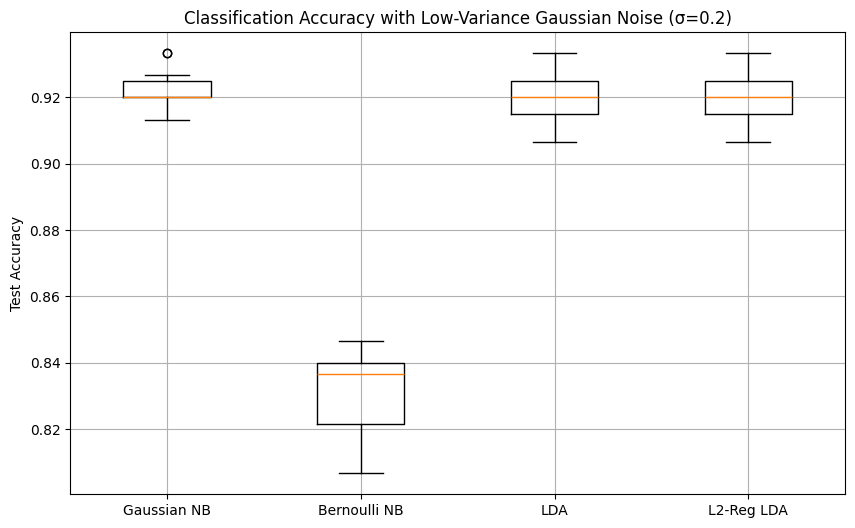

C:\Users\pnspo\AppData\Local\Temp\ipykernel_2396\3696899040.py:36: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(accs_high, labels=['Gaussian NB', 'Bernoulli NB', 'LDA', 'L2-Reg LDA'])


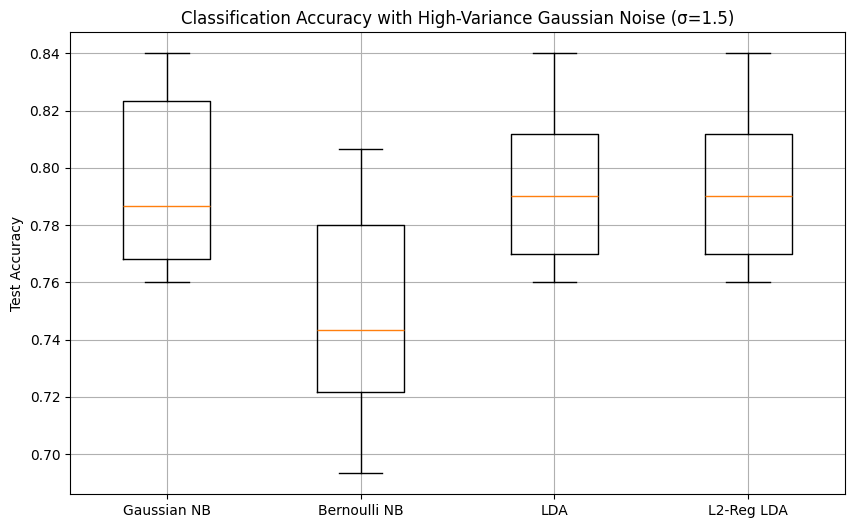

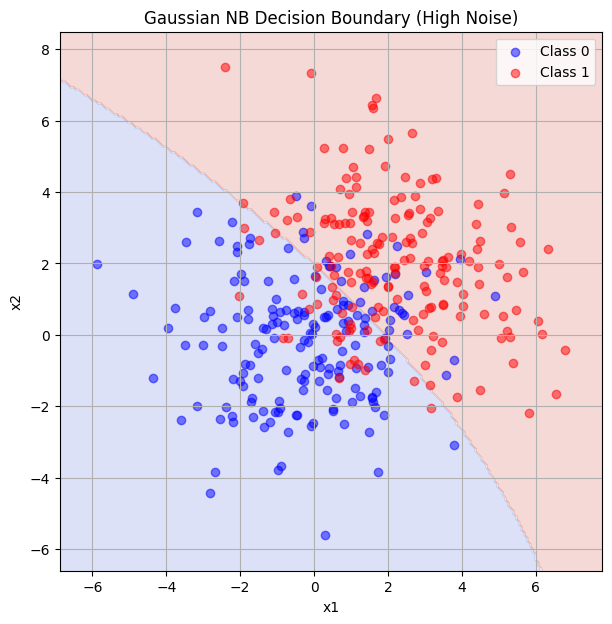

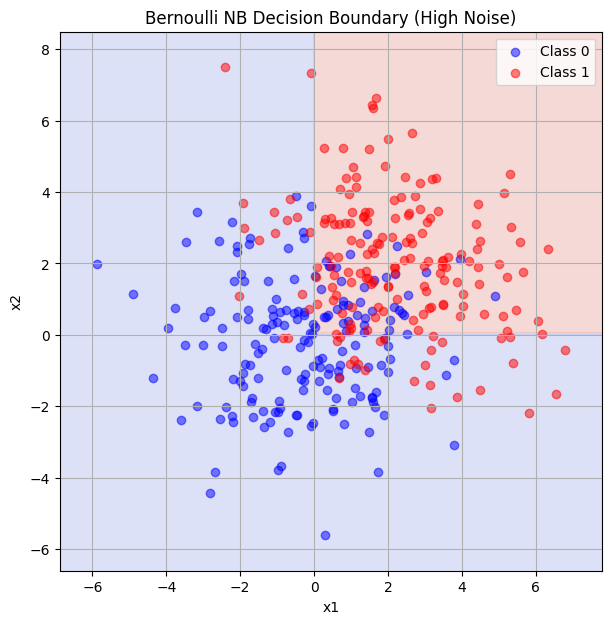

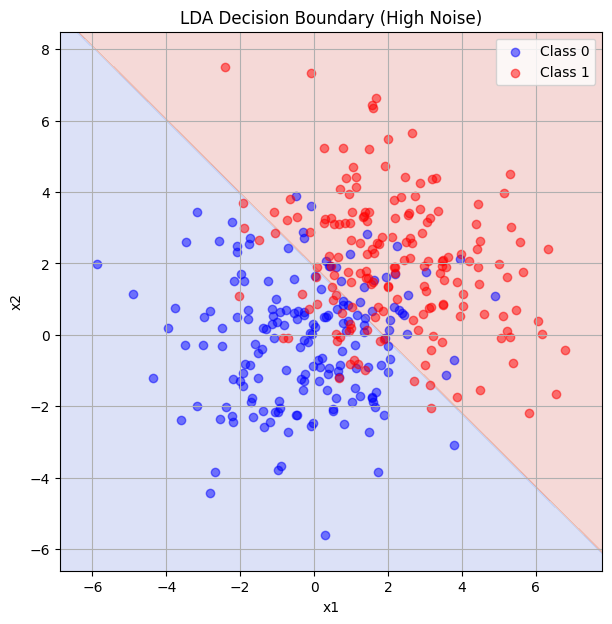

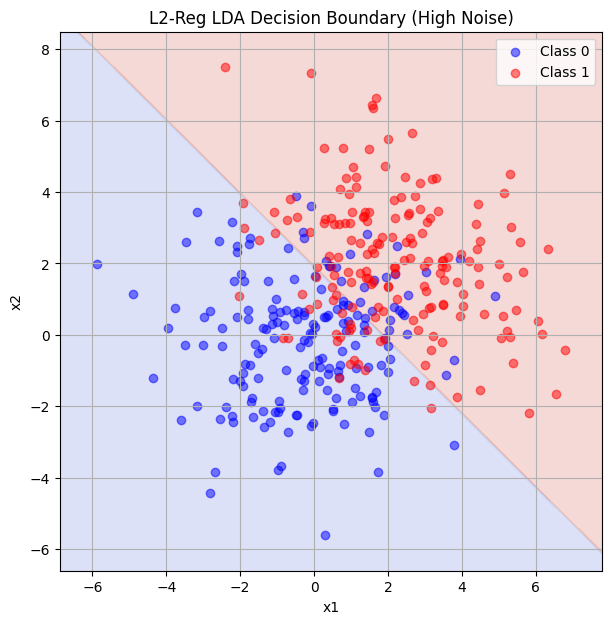

In [48]:
import numpy as np
import matplotlib.pyplot as plt

def run_noisy_classifier_trials(noise_std, n_trials=10):
    acc_gnb, acc_bnb, acc_lda, acc_lda_reg = [], [], [], []
    for trial in range(n_trials):
        np.random.seed(42+trial)
        # applying noise to original train set
        X_train_noisy = X_train + np.random.normal(0, noise_std, X_train.shape)
        X_test_noisy = X_test + np.random.normal(0, noise_std, X_test.shape)

        gnb_ = GaussianNaiveBayes(); gnb_.fit(X_train_noisy, y_train)
        bnb_ = BernoulliNaiveBayes(); bnb_.fit(X_train_noisy, y_train)
        lda_ = LinearDiscriminantAnalysis(); lda_.fit(X_train_noisy, y_train)
        lda_reg_ = L2RegularizedLDA(reg_lambda=0.1); lda_reg_.fit(X_train_noisy, y_train)

        acc_gnb.append(accuracy_score(y_test, gnb_.predict(X_test_noisy)))
        acc_bnb.append(accuracy_score(y_test, bnb_.predict(X_test_noisy)))
        acc_lda.append(accuracy_score(y_test, lda_.predict(X_test_noisy)))
        acc_lda_reg.append(accuracy_score(y_test, lda_reg_.predict(X_test_noisy)))

    return acc_gnb, acc_bnb, acc_lda, acc_lda_reg

# running trials for low variance noise ( = 0.2) and high variance noise ( = 1.5)
accs_low = run_noisy_classifier_trials(noise_std=0.2, n_trials=10)
accs_high = run_noisy_classifier_trials(noise_std=1.5, n_trials=10)

plt.figure(figsize=(10,6))
plt.boxplot(accs_low, labels=['Gaussian NB', 'Bernoulli NB', 'LDA', 'L2-Reg LDA'])
plt.title('Classification Accuracy with Low-Variance Gaussian Noise (=0.2)')
plt.ylabel('Test Accuracy')
plt.grid(True)
plt.show()

plt.figure(figsize=(10,6))
plt.boxplot(accs_high, labels=['Gaussian NB', 'Bernoulli NB', 'LDA', 'L2-Reg LDA'])
plt.title('Classification Accuracy with High-Variance Gaussian Noise (=1.5)')
plt.ylabel('Test Accuracy')
plt.grid(True)
plt.show()

# Visualize decision boundaries for high-noise trial
trial_idx = 0
X_train_noisy = X_train + np.random.normal(0, 1.5, X_train.shape)
X_test_noisy = X_test + np.random.normal(0, 1.5, X_test.shape)
gnb_noisy = GaussianNaiveBayes(); gnb_noisy.fit(X_train_noisy, y_train)
plot_decision_boundary(gnb_noisy, X_train_noisy, y_train, "Gaussian NB Decision Boundary (High Noise)")
bnb_noisy = BernoulliNaiveBayes(); bnb_noisy.fit(X_train_noisy, y_train)
plot_decision_boundary(bnb_noisy, X_train_noisy, y_train, "Bernoulli NB Decision Boundary (High Noise)")
lda_noisy = LinearDiscriminantAnalysis(); lda_noisy.fit(X_train_noisy, y_train)
plot_decision_boundary(lda_noisy, X_train_noisy, y_train, "LDA Decision Boundary (High Noise)")
lda_reg_noisy = L2RegularizedLDA(reg_lambda=0.1); lda_reg_noisy.fit(X_train_noisy, y_train)
plot_decision_boundary(lda_reg_noisy, X_train_noisy, y_train, "L2-Reg LDA Decision Boundary (High Noise)")


6.Robustness Analysis

Based on the experiments with Gaussian noise, class imbalance, and non-linear separability, the robustness of each classifier is as follows below:

- **Gaussian Naive Bayes (GNB):**
  - Performs well when features are truly Gaussian and independent.
  - Robust to moderate noise, but performance degrades with high noise or strong feature correlation.
  - Sensitive to class imbalance, as it relies on prior probabilities and likelihoods.

- **Bernoulli Naive Bayes (BNB):**
  - Less robust on continuous data, as binarization discards information.
  - More sensitive to noise and non-linear boundaries.
  - Can be more robust to class imbalance if features are well-separated after binarization.

- **Linear Discriminant Analysis (LDA):**
  - Most robust when class covariances are similar and data is close to Gaussian.
  - Handles moderate noise and class imbalance better than Naive Bayes.
  - Struggles with non-linear separability, as it can only produce linear boundaries.

- **L2-Regularized LDA:**
  - Adds robustness to LDA in the presence of high noise or small sample sizes by regularizing the covariance estimate.
  - Maintains similar performance to LDA on well-behaved data, but can outperform LDA when data is noisy or high-dimensional.

**From the above we can observe the following:**  
- LDA and L2-regularized LDA are generally the most robust to Gaussian noise and class imbalance in this setting.
- GNB is robust when its assumptions are met, but less so with correlated features or strong noise.
- BNB is least robust for continuous, noisy, or non-linearly separable data.
- None of the linear models are robust to non-linear separability; all will struggle if the true boundary is highly non-linear.